# Replication: Shafer et al. (2022)

*Association of the Implementation of Child Tax Credit Advance Payments With Food Insufficiency in US Households*, JAMA Network Open 5(1): e2143296.

This notebook reproduces the paper's main estimates from the analytic sample built in `data_prep.ipynb` (run that first).

**Design.** Households with children (treated) are compared with households without children (comparison), before and after the first advance CTC payment on July 15, 2021. Week 34 (Jul 21-Aug 2) is the first wave after the payment; week 33 (Jun 23-Jul 5) is the reference wave.

**Models.** Weighted linear probability models (WLS on the 0/1 outcome) with wave fixed effects, state fixed effects, the paper's covariates, the pooled household weight (`HWEIGHT / 13`), and standard errors clustered by state, with a t-distribution and 50 degrees of freedom.

**Replication targets** (success criteria from the proposal):

| Quantity | Paper |
|---|---|
| Unadjusted food insufficiency, households with children, week 33 / 34 | 14.3% / 9.9% |
| Event-study coefficient, week 34 ($\beta_{34}$) | -0.037 (95% CI -0.055 to -0.019), P < .001 |
| Pooled difference-in-differences | -0.022, P = .001 |

A replication succeeds if $\beta_{34}$ has the same sign and significance with a point estimate inside the original 95% CI, and the DiD estimate is near -0.022.

## Setup

In [27]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from modules import prepare_pulse, analysis

a = analysis.add_model_vars(prepare_pulse.load("analytic_sample"))
assert len(a) == 585_170, f"Expected 585,170 rows, got {len(a):,}. Re-run data_prep.ipynb."
print(f"{len(a):,} respondents | {a.state.nunique()} states | weeks {a.WEEK.min()}-{a.WEEK.max()}")

585,170 respondents | 51 states | weeks 22-34


## 1. Unadjusted food insufficiency by week

Weighted share of households reporting food insufficiency, by wave and by whether children are present. This is the raw pattern the models formalize: if the payment mattered, the gap between the two lines should narrow in week 34.

In [28]:
rates = analysis.weighted_rates(a)
rates["Gap (children - none)"] = rates["Children"] - rates["No children"]
rates.round(1)

kids,No children,Children,Gap (children - none)
WEEK,,,
22,11.1,15.2,4.1
23,11.3,14.8,3.5
24,11.7,14.8,3.1
25,10.6,14.6,4.0
26,10.8,14.3,3.6
27,9.5,11.5,2.0
28,8.5,11.0,2.5
29,9.2,11.3,2.0
30,9.6,12.4,2.8


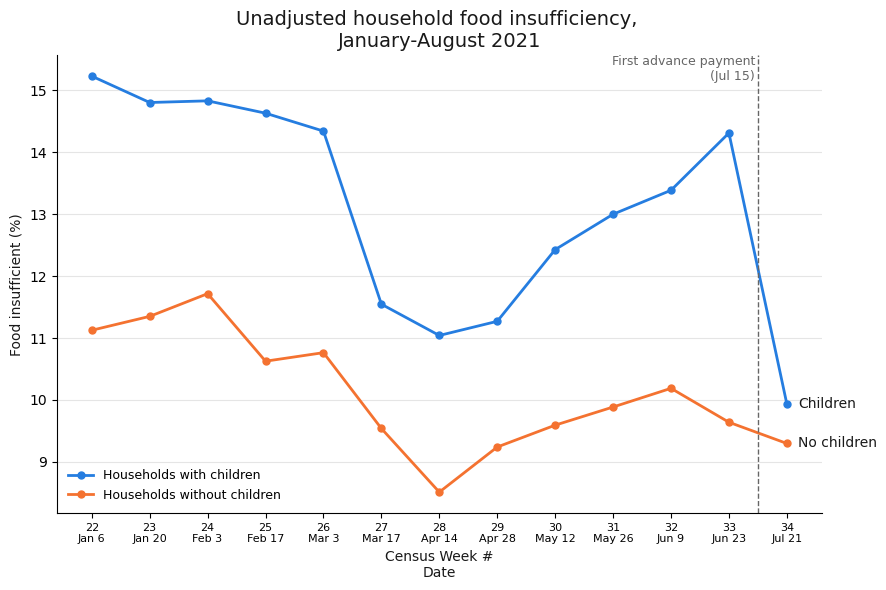

In [29]:
BLUE, ORANGE, INK, MUTED, GRID = "#257de0", "#f47230", "#191919", "#666666", "#e5e5e5"

fig, ax = plt.subplots(figsize=(9, 6))
x = rates.index.values
for col, color in [("Children", BLUE), ("No children", ORANGE)]:
    ax.plot(x, rates[col], color=color, lw=2, marker="o", ms=5, label=f"Households with {col.lower()}" if col == "Children" else "Households without children")
    ax.annotate(col, (x[-1], rates[col].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color=INK, fontsize=10)
ax.axvline(33.5, color=MUTED, ls="--", lw=1)
ax.text(33.45, ax.get_ylim()[1], "First advance payment\n(Jul 15)", ha="right", va="top", color=MUTED, fontsize=9)
ax.set_xticks(x, [f"{w}\n{analysis.WEEK_START[w]}" for w in x], fontsize=8)
ax.set_ylabel("Food insufficient (%)", color=INK)
ax.set_xlabel("Census Week #\nDate", color=INK)
ax.set_title("Unadjusted household food insufficiency, \nJanuary-August 2021", loc="center", color=INK, fontsize=14)
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.legend(frameon=False, loc="lower left", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "unadjusted_food_insufficiency.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation.** Food insufficiency among households with children falls from 14.3% in week 33 to 9.9% in week 34, while households without children barely move (9.6% to 9.3%). The gap between the two groups shrinks from 4.7 to 0.6 percentage points, the smallest of any wave.

Two features matter for the models below:

- **The gap was not flat before the payment.** It ran about 3-4 points in January-early March (weeks 22-26), narrowed to about 2-2.5 points from mid-March to early May (weeks 27-29), then widened again to 4.7 in late June (week 33), its largest value.
- **Week 33, the reference wave, is the high point of the pre-period gap.** Because every event-study coefficient is measured against week 33, this choice affects how large the week-34 drop looks (see Section 4).

## 2. Pooled difference-in-differences

`kids_post` = 1 for households with children in week 34. Its coefficient is the change in food insufficiency for households with children after the payment, relative to the change for households without children. `post` itself is absorbed by the wave fixed effects. **Target: -0.022 (P = .001).**

In [30]:
# Main DiD model: state-clustered SEs with a t-distribution (G - 1 = 50 df), the default in analysis.fit_wls
did = analysis.fit_wls(analysis.did_formula(), a)
did_ci = did.conf_int().loc["kids_post"]
print(f"DiD (kids_post): {did.params['kids_post']:.4f}  95% CI {did_ci[0]:.4f} to {did_ci[1]:.4f}  "
      f"p = {did.pvalues['kids_post']:.4f}   (paper: -0.022, P = .001)")
print("Degrees of freedom used for inference:", did.df_resid_inference)

DiD (kids_post): -0.0221  95% CI -0.0343 to -0.0100  p = 0.0006   (paper: -0.022, P = .001)
Degrees of freedom used for inference: 50


In [31]:
# Comparison: the same model with statsmodels' normal-distribution p-values
did_normal = analysis.fit_wls(analysis.did_formula(), a, use_t=False)
print(f"p-value, t-distribution (50 df): {did.pvalues['kids_post']:.4f}")
print(f"p-value, normal distribution:    {did_normal.pvalues['kids_post']:.4f}   (paper: .001)")

p-value, t-distribution (50 df): 0.0006
p-value, normal distribution:    0.0002   (paper: .001)


**Interpretation.** The pooled DiD estimate is **-0.0221**, a 2.2-percentage-point reduction in food insufficiency for households with children after the first payment, relative to households without children. This matches the paper's -0.022.

All models use state-clustered standard errors with a t-distribution and clusters - 1 = 50 degrees of freedom. With this, p = 0.0006, close to the paper's reported P = .001; statsmodels' default normal distribution gives p = 0.0002. The t-distribution brings the p-value much closer to the paper's and reproduces the paper's event-study confidence interval exactly (Section 3), so the paper most likely used small-sample cluster inference. The remaining small difference may reflect how the paper reported its p-value (under JAMA's convention, 0.0006 would usually appear as P < .001) or a minor difference in the standard-error correction. The coefficient is the same under both approaches; the t-based confidence interval is slightly wider.

The DiD compares week 34 with the **average** of all 12 pre-payment waves, so it is smaller than the event-study estimate, which compares week 34 with week 33 alone.

## 3. Event study

The children indicator is interacted with every wave, with week 33 as the reference. Each coefficient is the gap between households with and without children in that wave, relative to the gap in week 33. $\beta_{34}$ is the estimate of interest. **Target: -0.037 (95% CI -0.055 to -0.019).**

In [32]:
es = analysis.fit_wls(analysis.event_study_formula(), a)
es_table = analysis.event_study_table(es)
es_table.round(4)

,week,coef,se,lo,hi,p,start
0,22,-0.0092,0.0086,-0.0265,0.0081,0.2902,Jan 6
1,23,-0.0095,0.0117,-0.0329,0.0140,0.4206,Jan 20
2,24,-0.0157,0.0113,-0.0383,0.0070,0.1706,Feb 3
3,25,-0.0082,0.0063,-0.0209,0.0045,0.1995,Feb 17
4,26,-0.0130,0.0077,-0.0285,0.0025,0.0977,Mar 3
5,27,-0.0230,0.0062,-0.0355,-0.0105,0.0005,Mar 17
6,28,-0.0226,0.0087,-0.0400,-0.0052,0.0119,Apr 14
7,29,-0.0264,0.0094,-0.0452,-0.0075,0.0070,Apr 28
8,30,-0.0199,0.0088,-0.0375,-0.0022,0.0281,May 12
9,31,-0.0164,0.0077,-0.0318,-0.0010,0.0376,May 26


In [33]:
b34 = es_table.set_index("week").loc[34]
inside = -0.055 <= b34.coef <= -0.019
print(f"beta_34 = {b34.coef:.4f}  95% CI {b34.lo:.4f} to {b34.hi:.4f}  p = {b34.p:.4g}")
print("Point estimate inside the paper's 95% CI:", inside)

beta_34 = -0.0367  95% CI -0.0547 to -0.0187  p = 0.0001562
Point estimate inside the paper's 95% CI: True


**Interpretation.** The week-34 event-study coefficient is **-0.0367 (95% CI -0.0547 to -0.0187, p < .001)**: relative to the week-33 gap, the gap between households with and without children fell by 3.7 percentage points in the first wave after the payment. This reproduces the paper's -0.037 (-0.055 to -0.019) exactly at the reported precision, and meets the proposal's success criterion: same sign, same significance, point estimate inside the original CI.

Relative to the 14.3% week-33 rate for households with children, a 3.7-point drop is about a 26% reduction, consistent with the paper's 25.9%.

## 4. Parallel trends

The event-study design assumes that, without the payment, food insufficiency would have moved in parallel for households with and without children. The pre-period coefficients (weeks 22-32) are the check: they should sit near zero with no trend. The joint F-test asks whether they are all zero together.

In [34]:
pt = analysis.pretrend_test(es)
print(f"Joint test that weeks 22-32 coefficients are all zero: F = {float(np.squeeze(pt.fvalue)):.2f}, p = {float(pt.pvalue):.4f}")

Joint test that weeks 22-32 coefficients are all zero: F = 3.46, p = 0.0013


**Interpretation.** The joint test **rejects** the hypothesis that all pre-payment coefficients are zero (F = 3.46, p = 0.0013). Formally, the parallel-trends assumption is not supported when week 33 is the reference.

The coefficient table shows where this comes from. Weeks 27-31 (mid-March to early June) are all negative and individually significant, from -0.016 to -0.026: the gap between households with and without children was 2-3 points **smaller** in spring than in week 33. Weeks 22-26 and 32 are closer to zero and not significant.

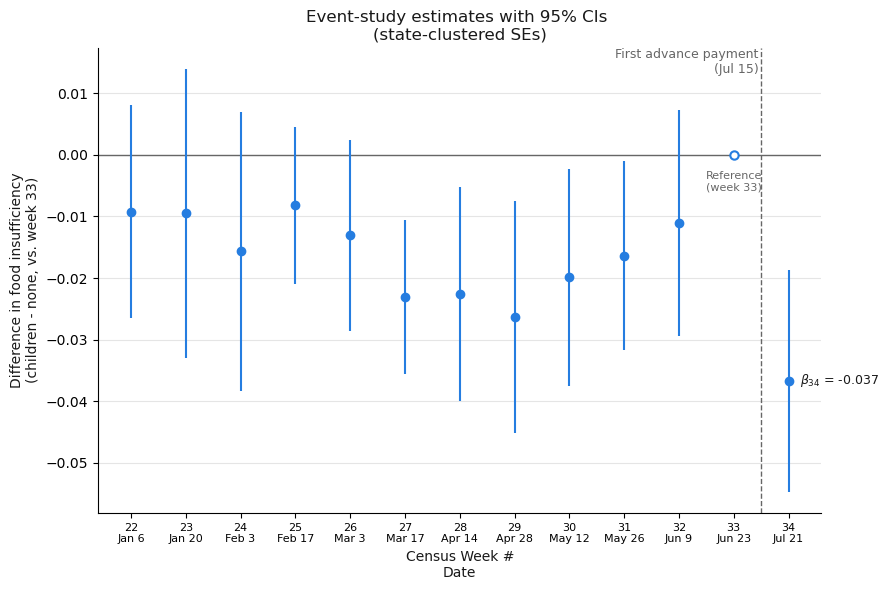

In [35]:
t = es_table
fig, ax = plt.subplots(figsize=(9, 6))
ax.axhline(0, color=MUTED, lw=1)
ax.axvline(33.5, color=MUTED, ls="--", lw=1)
est = t[t.week != analysis.REF_WEEK]
ax.errorbar(est.week, est.coef, yerr=[est.coef - est.lo, est.hi - est.coef], fmt="o", ms=6,
            color=BLUE, ecolor=BLUE, elinewidth=1.5, capsize=0)
ax.plot([analysis.REF_WEEK], [0], "o", ms=6, mfc="white", mec=BLUE, mew=1.5)
ax.annotate("Reference\n(week 33)", (analysis.REF_WEEK, 0), xytext=(0, -26), textcoords="offset points",
            ha="center", color=MUTED, fontsize=8)
ax.annotate(rf"$\beta_{{34}}$ = {b34.coef:.3f}", (34, b34.coef), xytext=(8, 0), textcoords="offset points",
            va="center", color=INK, fontsize=9)
ax.text(33.45, ax.get_ylim()[1], "First advance payment\n(Jul 15)", ha="right", va="top", color=MUTED, fontsize=9)
ax.set_xticks(t.week, [f"{w}\n{s}" for w, s in zip(t.week, t.start)], fontsize=8)
ax.set_ylabel("Difference in food insufficiency\n(children - none, vs. week 33)", color=INK)
ax.set_xlabel("Census Week #\nDate", color=INK)
ax.set_title("Event-study estimates with 95% CIs \n(state-clustered SEs)", loc="center", color=INK)
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "event_study_estimates.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation of the plot, and what it means for the result.**

The pre-period estimates dip in spring and return toward zero by June, rather than showing a steady trend. One plausible explanation, to be checked rather than assumed, is the third round of Economic Impact Payments under the American Rescue Plan, which began reaching households in mid-March 2021 (week 27). Those payments included $1,400 per dependent, so they were larger for households with children. A temporary narrowing of the gap at that time is what the CTC hypothesis itself would predict for a cash payment. A second possible factor is the end of the school year in June, when children lose access to school meals; this would make week 33 the most comparable reference for week 34 (see Section 5b).

This has two implications:

1. **The paper's estimate replicates, but its magnitude depends on the reference wave.** Week 33 has the widest pre-period gap, so measuring against it makes the week-34 drop look largest (-0.037). Measured against the average pre-period gap, the DiD gives -0.022. Both are negative and significant, so the direction of the finding is robust; the size is less certain.
2. **The pre-trend failure is a substantive replication finding**, not a coding error. Section 5b re-estimates $\beta_{34}$ against different reference periods to show how much its size depends on this choice.

## 5. Robustness: logistic difference-in-differences

The linear probability model can predict values outside 0-1. As a check, the same DiD is fit as a weighted logistic regression, and the effect is converted back to probability units (the average marginal effect of `kids_post` among households with children in week 34) so it is comparable with the estimate above.

In [36]:
fitted = did.fittedvalues
print(f"LPM fitted values outside [0, 1]: {((fitted < 0) | (fitted > 1)).mean():.1%}")

logit, ame = analysis.did_logit_ame(a)
print(f"Logistic DiD, average marginal effect of kids_post: {ame:.4f}   (LPM: {did.params['kids_post']:.4f})")

print(f"  below 0: {(fitted < 0).mean():.1%}   above 1: {(fitted > 1).mean():.1%}")

LPM fitted values outside [0, 1]: 27.8%


c:\Users\Rosey\anaconda3\envs\CSS211\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(


Logistic DiD, average marginal effect of kids_post: -0.0213   (LPM: -0.0221)
  below 0: 27.8%   above 1: 0.0%


**Interpretation.**

- **27.8% of the linear probability model's fitted values fall outside 0-1**, all of them predicted probabilities below zero (27.8% below 0, none above 1) for low-risk households in a sample where only about 10% are food insufficient. This is a known weakness of linear probability models with a rare outcome, and it is why the logistic check matters.
- **The logistic DiD gives an average marginal effect of -0.0213**, nearly identical to the LPM's -0.0221. The estimated effect of the payment does not depend on the linear model's out-of-range predictions.
- The `SpecificationWarning` says statsmodels does not fully support clustered standard errors with `var_weights` in a GLM. The point estimate (the AME) is unaffected, but the logistic model's clustered SEs should not be reported. If an SE for the AME is needed, the replicate-weight method from Extension (b) is a better route.

## 5b. Sensitivity of $\beta_{34}$ to the reference period

The pre-trend test (Section 4) shows the gap between households with and without children was not stable before the payment, and week 33, the paper's reference, has the widest pre-period gap. This section re-estimates $\beta_{34}$ against different reference periods to show how much the estimated drop depends on that choice:

| Reference | Why |
|---|---|
| Week 33 | The paper's specification (should reproduce -0.037) |
| Week 32 | The adjacent pre-payment week |
| Weeks 22-26 pooled | January-early March, before the spring narrowing of the gap |
| Weeks 22-33 pooled | All pre-payment weeks; equivalent to the pooled DiD (should reproduce -0.022) |

The first and last rows double as checks: they should match Sections 3 and 2.

In [37]:
references = {
    "Week 33 (paper)": [33],
    "Week 32": [32],
    "Weeks 22-26 pooled": range(22, 27),
    "Weeks 22-33 pooled (= DiD)": range(22, 34),
}
sens = analysis.beta34_by_reference(a, references)
sens.round(4)

,reference,beta34,lo,hi,p,n_pre_coefs,pretrend_F,pretrend_p
0,Week 33 (paper),-0.0367,-0.0547,-0.0187,0.0002,11,3.4553,0.0013
1,Week 32,-0.0256,-0.0444,-0.0068,0.0086,11,3.4553,0.0013
2,Weeks 22-26 pooled,-0.0256,-0.0376,-0.0135,0.0001,7,4.0498,0.0014
3,Weeks 22-33 pooled (= DiD),-0.0221,-0.0343,-0.0100,0.0006,0,NaN,NaN


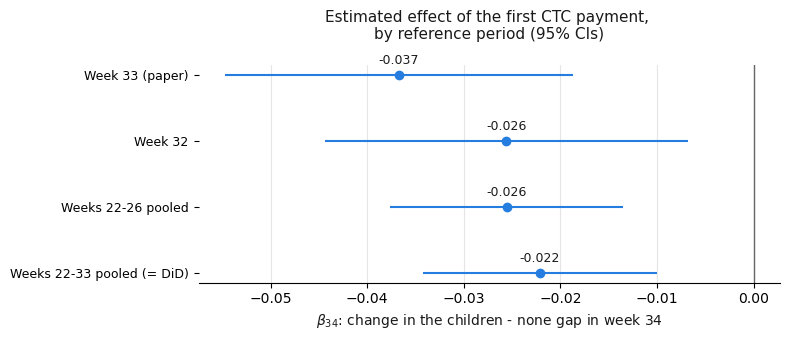

In [38]:
fig, ax = plt.subplots(figsize=(8, 3.5))
y = np.arange(len(sens))[::-1]
ax.errorbar(sens.beta34, y, xerr=[sens.beta34 - sens.lo, sens.hi - sens.beta34], fmt="o", ms=6,
            color=BLUE, ecolor=BLUE, elinewidth=1.5, capsize=0)
for yi, b in zip(y, sens.beta34):
    ax.annotate(f"{b:.3f}", (b, yi), xytext=(0, 8), textcoords="offset points", ha="center", color=INK, fontsize=9)
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(y, sens.reference, fontsize=9)
ax.set_xlabel(r"$\beta_{34}$: change in the children - none gap in week 34", color=INK)
ax.set_title("Estimated effect of the first CTC payment, \nby reference period (95% CIs)\n", loc="center", color=INK, fontsize=11)
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "beta34_by_reference.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation.** The estimated effect of the first payment is negative and statistically significant under every reference period, but its size depends on the comparison:

| Reference | $\beta_{34}$ | 95% CI | p |
|---|---|---|---|
| Week 33 (paper) | -0.037 | -0.055 to -0.019 | < .001 |
| Week 32 | -0.026 | -0.044 to -0.007 | .009 |
| Weeks 22-26 pooled | -0.026 | -0.038 to -0.014 | < .001 |
| Weeks 22-33 pooled (= DiD) | -0.022 | -0.034 to -0.010 | < .001 |

- **The paper's reference week gives the largest estimate.** Week 33 had the widest pre-payment gap (4.7 points), so the drop to week 34 looks largest against it. Against the adjacent week or the January-early March baseline, the estimate is about 2.6 points, roughly 30% smaller than the paper's 3.7.
- **The finding is robust in direction and significance.** No reference period produces an estimate near zero; every confidence interval excludes zero.
- **The pre-trend problem does not go away with a different single reference week.** The joint test for week 32 is identical to the one for week 33 (F = 3.46, p = .001), because with one reference week the test asks whether all pre-payment gaps were equal, and changing the reference only relabels the coefficients. Against the pooled January-early March baseline, weeks 27-33 also differ significantly (F = 4.05, p = .001), consistent with the spring narrowing of the gap seen in Section 4.
- **Seasonality may favor the paper's reference week.** The pre-payment gap moved in two directions. It narrowed in spring (weeks 27-31), possibly because of the third round of Economic Impact Payments, which were larger for households with children. It then widened in June, possibly because children lose access to school meals when the school year ends. If the June increase is seasonal, it would continue into week 34 (late July), when school meals are still unavailable. Week 33 is then the comparison most like week 34, and references from the school year (weeks 22-26, and partly week 32) would understate the payment's effect, because without the payment the summer gap would likely have stayed above its school-year level. This data contains only one summer, so this explanation cannot be tested here.

**Bottom line:** the first advance CTC payment is associated with a reduction in food insufficiency among households with children of about **2.2 to 3.7 percentage points**, depending on the comparison period. The paper's 3.7-point estimate is the largest of these, but it is not necessarily an overstatement: if the June rise in the gap reflects the loss of school meals, week 33 is the most comparable reference for a summer week, and the smaller estimates from school-year baselines would understate the effect.

## 6. Replication summary

In [39]:
def fmt_p(p):
    """JAMA-style p-value: '< .001' below 0.001, otherwise 3 decimals without the leading zero."""
    return "< .001" if p < 0.001 else f"{p:.3f}".lstrip("0")

summary = pd.DataFrame([
    ["Analytic sample (n)", "585,170", f"{len(a):,}"],
    ["Unadjusted, children, week 33", "14.3%", f"{rates.loc[33, 'Children']:.1f}%"],
    ["Unadjusted, children, week 34", "9.9%", f"{rates.loc[34, 'Children']:.1f}%"],
    ["Event study beta_34 (95% CI)", "-0.037 (-0.055 to -0.019)", f"{b34.coef:.3f} ({b34.lo:.3f} to {b34.hi:.3f})"],
    ["Event study beta_34 p-value", "< .001", fmt_p(b34.p)],
    ["DiD (95% CI)", "-0.022", f"{did.params['kids_post']:.3f} ({did_ci[0]:.3f} to {did_ci[1]:.3f})"],
    ["DiD p-value", ".001", f"{fmt_p(did.pvalues['kids_post'])} ({did.pvalues['kids_post']:.4f})"],
    ["Pre-trend joint test p-value", "n/a", fmt_p(float(pt.pvalue))],
    ["Logistic DiD (AME)", "n/a", f"{ame:.3f}"],
], columns=["Quantity", "Paper", "Ours"])
summary

,Quantity,Paper,Ours
0,Analytic sample (n),"585,170","585,170"
1,"Unadjusted, children, week 33",14.3%,14.3%
2,"Unadjusted, children, week 34",9.9%,9.9%
3,Event study beta_34 (95% CI),-0.037 (-0.055 to -0.019),-0.037 (-0.055 to -0.019)
4,Event study beta_34 p-value,< .001,< .001
5,DiD (95% CI),-0.022,-0.022 (-0.034 to -0.010)
6,DiD p-value,.001,< .001 (0.0006)
7,Pre-trend joint test p-value,n/a,.001
8,Logistic DiD (AME),n/a,-0.021


## Overall assessment

**The replication succeeds on every pre-specified criterion:**

| Criterion | Result |
|---|---|
| Analytic sample and unadjusted rates match | Exact: 585,170; 14.3%; 9.9% |
| $\beta_{34}$ same sign and significance, inside paper's CI | -0.037 (95% CI -0.055 to -0.019, p < .001): identical to the paper at its reported precision |
| DiD near -0.022 | -0.022 (95% CI -0.034 to -0.010; p = 0.0006 vs. the paper's .001) |

Inference uses state-clustered standard errors with a t-distribution and G - 1 = 50 degrees of freedom, which reproduces the paper's event-study confidence interval exactly and brings the DiD p-value close to the paper's (0.0006 vs. .001); the Methods do not state this choice.

**Beyond the original paper:**

1. The pre-period event-study coefficients jointly reject parallel trends (p = .001), driven by a narrowing of the gap in spring 2021 that may coincide with the third round of stimulus payments. The direction and significance of the CTC finding hold under every reference period tested, but its size ranges from 2.2 to 3.7 percentage points (Section 5b); the paper's estimate is the largest, and may be the most appropriate if the June rise in the gap is seasonal.
2. The effect is robust to functional form: a logistic model gives nearly the same effect in probability units (-0.021 vs. -0.022).
3. Extension (b) will test whether inference changes under Census replicate weights instead of state clustering.

## Notes on modeling choices

These are choices the paper's Methods do not fully specify; each is a candidate for a sensitivity check if an estimate misses its target.

- **Age group:** 18-24, 25-44, 45-64, from birth year.
- **Race and ethnicity:** Hispanic (any race), then non-Hispanic White, Black, Asian, and other or multiple races.
- **Number of adults and children:** entered as counts. Number of children can't enter as categories alongside the `kids` indicator, because "0 children" and `kids = 0` would be the same variable.
- **Missing-as-category:** income, health insurance, SNAP, food aid and employment keep missing (-1) as a separate category, which is how the analytic sample was reproduced (see `data_prep.ipynb`).
- **Health insurance:** one variable, covered by any type vs. none.

**Next:** `extensions.ipynb` for Extension (b), replicate-weight standard errors, and Extension (a), the state mixed model.